# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isnull().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isnull().sum())# Cantidad de valores nulos)
print(usage.isna().mean())# Proporción de valores nulos)

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint: 
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Las columnas city y churn_date del dataset 'users' tienen un 11.73% y un 88.35% de valores faltantes respectivamente.
- Las columnas date, duration y length del dataset 'usage tienen un 0.13%, 55.19% y un 44.74% de valores faltantes respectivamente.

- Indica qué harías: ¿imputar, eliminar, ignorar?
- La columna city se debe de investigar para imputar o dejar como nulos, dado que solo tiene un 11.73% de nulos.
- La columna churn_date debería de ignorarse o elimnarse, porque tiene mas de 88% de datos nulos.
- El porcentaje de nulos en columna date es muy baja, apenas del 0.13% así que bien podrían imputarse o dejarse como nulos.
- La columna duration tiene una elevada cantidad de nulos, por lo que la recomendación sería investigar para tomar la decisión de imputar,  eliminar o dejar como nulos.
- La columna length tiene una elevada cantidad de nulos, por lo que la recomendación sería investigar para tomar la decisión de imputar,  eliminar o dejar como nulos.



### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
print(users[['user_id','age']].describe())


            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` tiene una desviación estándar con variabilidad baja, no se obervan valores extremos considerables y su media y mediana son iguales, lo que quiere decir que no hay sesgos.
- La columna `age`tiene una desviación estándar con alta variabilidad, se observan valores mínimos muy extremos y su media y mediana son diferentes, lo que indica que hay sesgos.

In [13]:
# explorar columnas numéricas de usage
print(usage[['id','user_id','duration','length']].describe())

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` tienen medias y medianas iguales o similares, lo que indica que no hay sesgos considerables, pero `id` tiene una desviación estándar muy alta, lo que indica que sus datos estan muy distribuidos; mientras que `user_id` tiene una desviación estandar baja, lo cual indica que los datos en esta columna estan mas agrupados.
- Las columnas `duration` y `user_id`tienen medias y medianas similares, sin embargo ambas tienen valores maximos muy alejados de la media, por lo que podría haber sesgos, esto se refleja también en su elevada desviación estándar.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())
print("") 

for col in columnas_user:
    print(col)
    print("Frecuencia absoluta:")
    print(users[col].value_counts())
    print("\nFrecuencia relativa:")
    print(users[col].value_counts(normalize=True))
    print("") 

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595

city
Frecuencia absoluta:
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Frecuencia relativa:
Bogotá      0.228830
CDMX        0.206740
Medellín    0.174455
GDL         0.127443
Cali        0.120079
MTY         0.115265
?           0.027188
Name: city, dtype: float64

plan
Frecuencia absoluta:
Basico     2595
Premium    1405
Name: plan, dtype: int64

Frecuencia relativa:
Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64



- La columna `city` cuenta con 3531 valores de los cuales siete son únicos, es decir, solo hay siete ciudades, las cuales son: Bogotá, CDMX, Medellín, GDL, Cali y Mty, aunque hay una que no cuenta con nombre solo un signo de interogación(?). La ciudad con mayor frecuencia relativa es Bogotá, con una frecuencia absoluta de 808.
- La columna `plan` cuenta con 4000 valores de los cuales dos son únicos, es decir, solo hay dos tipos de planes: Basico y Premium. El plan con mayor frecuencia relativa es el Básico, con una frecuencia absoluta de 2595. 

In [15]:
# explorar columna categórica de usage
print(usage['type'].describe())
print("")

print("Frecuencia absoluta:")
print(usage['type'].value_counts())

print("\nFrecuencia relativa:")
print(usage['type'].value_counts(normalize=True))  

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

Frecuencia absoluta:
text    22092
call    17908
Name: type, dtype: int64

Frecuencia relativa:
text    0.5523
call    0.4477
Name: type, dtype: float64


- La columna `type` cuenta con 40000 valores de los cuales dos son únicos, es decir, solo hay dos tipos: text y call. El tipo con mayor frecuencia relativa es text, con una frecuencia absoluta de 22092.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En la columna 'age' hay un sentinel el cual es -999, mientras que en la columna 'city' hay un sentinel con signo de interrogación(?).
- ¿Qué acción tomarías?
- Reemplazar el sentinel -999 por la mediana y '?' por valores nulos. 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors="coerce")


In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors="coerce")

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, hay 1330 valores en el año 2024, 1316 en el año 2023, 1314 en el año 2022 y 40 en el año 2026.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()


2024.0    39950
Name: date, dtype: int64

En `date`, solo hay valores en el año 2024 y tiene 39950 de ellos.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Sí, aparecen datos del año 2026, lo cual es imposible, ya que solamente tenemos datos registrados hasta el año 2024.
- ¿Qué harías con ellas?
- No las tomaría en cuenta para el análisis, serían nulas.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, pd.NA)
users['age'] = users['age'].fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()



count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:

# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date'].dt.year.replace(2026,pd.NA)

# Verificar cambios
users['reg_date'].value_counts()


2024    1330
2023    1316
2022    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False) 


type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False) 


type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

- Los valores faltantes en la columna 'duration' dependen completamente de 'text', debido a que la esta columna cuenta la duración de una llamada y no se puede medir la duración en tiempo de un mensaje, por lo cual, es lógico que todos esos valores sean nulos.
- Los valores faltantes en la columna 'length' dependen completamente de 'call', debido a que la esta columna cuenta el largo de un texto y no se puede medir el largo de una llamada, sino su duraci, por lo cual, es lógico que todos esos valores sean nulos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas
usage['minutos'] = (usage['duration'])

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')['is_text','is_call','minutos'].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,minutos
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text": "cant_mensajes", "is_call": "cant_llamadas", "minutos": "cant_minutos_llamada"}) 

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile_2024 = user_profile[user_profile['reg_date'] == 2024]
user_profile_2024[['age','cant_mensajes','cant_llamadas','cant_minutos_llamada']].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,1330.000000,1330.000000,1330.000000,1330.000000
mean,48.414286,5.500000,4.557143,24.126669
std,17.963443,2.382293,2.140329,19.458620
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.332500
50%,48.000000,5.000000,4.000000,20.325000
75%,64.000000,7.000000,6.000000,32.542500
max,79.000000,16.000000,13.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile_2024['plan'].value_counts(normalize=True)

Basico     0.656391
Premium    0.343609
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

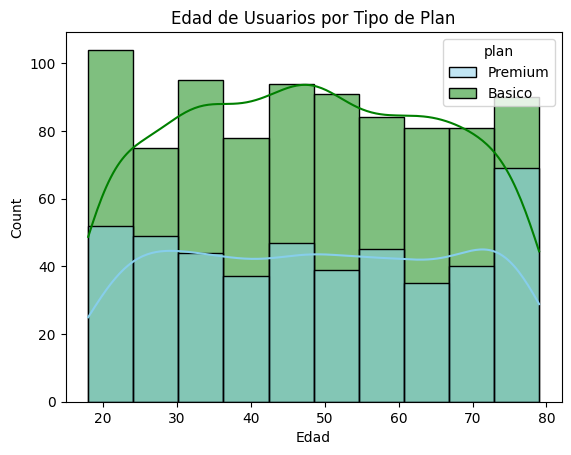

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile_2024, x='age', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Edad')
plt.title('Edad de Usuarios por Tipo de Plan')

plt.show()

💡Insights: 
- Dentro del plan Premium, el grupo mas grande es el que se encuentra entre los 70 y los 80 años de edad, mientras que dentro del plan Básico el grupo mas grande es el que se encuentra alredeador de los 20 años de edad. Aún así, la distribución de los datos es casi simétrica.
  

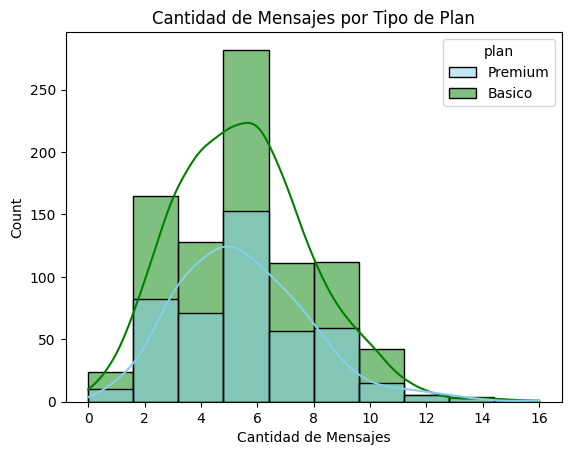

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile_2024, x='cant_mensajes', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Cantidad de Mensajes')
plt.title('Cantidad de Mensajes por Tipo de Plan')

plt.show()

💡Insights: 
- La distribución de los datos es mas o menos simétrica, y en ambos tipos de plan la mayor proporción de usuarios envía entre 5 y 6 mensajes.

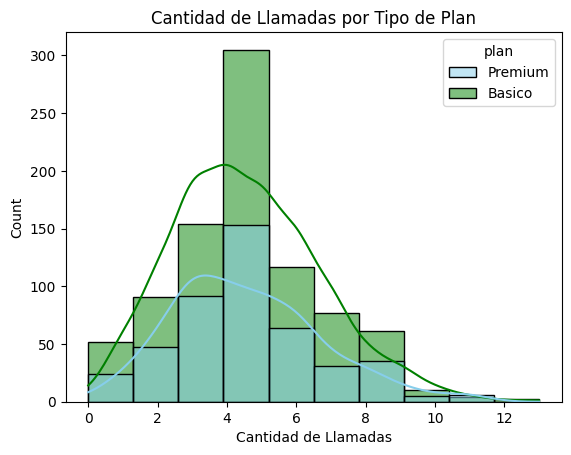

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile_2024, x='cant_llamadas', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Cantidad de Llamadas')
plt.title('Cantidad de Llamadas por Tipo de Plan')

plt.show()

💡Insights: 
- La distribución de los datos es mas o menos simétrica, y en ambos tipos de plan la mayor proporción de usuarios realiza entre 4 y 5 llamadas.

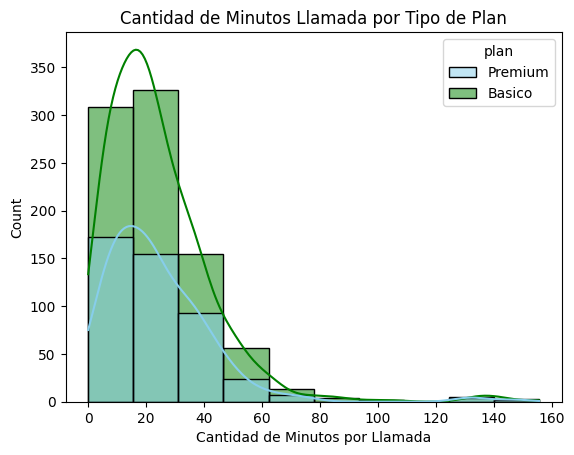

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile_2024, x='cant_minutos_llamada', hue='plan', bins=10, palette=['skyblue','green'], kde=True)

plt.xlabel('Cantidad de Minutos por Llamada')
plt.title('Cantidad de Minutos Llamada por Tipo de Plan')

plt.show()


💡Insights: 
- Los datos no se distribuyen uniformemente, sino que esta sesgada a la derecha. Esto muestra que la mayoría de los usuarios tanto del plan Premium como del Básico realizan llamadas entre 1 y 30 minutos, aunque hay una pequeña proporción que realiza llamadas de mas de 80 minutos y hasta casi 160.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>
- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
- Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

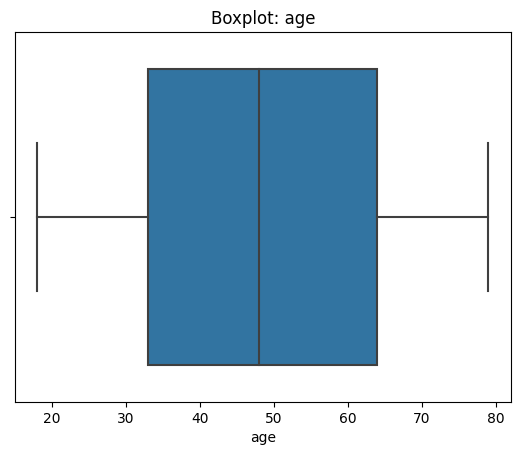

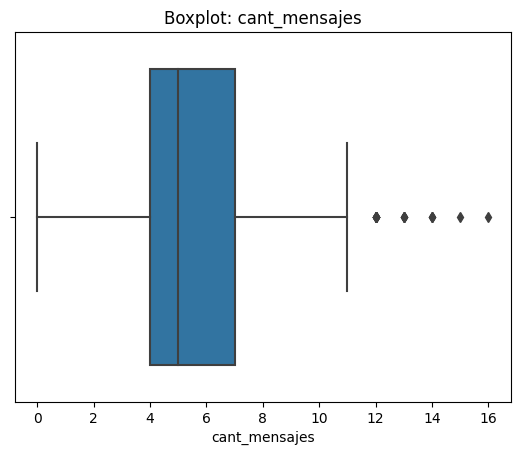

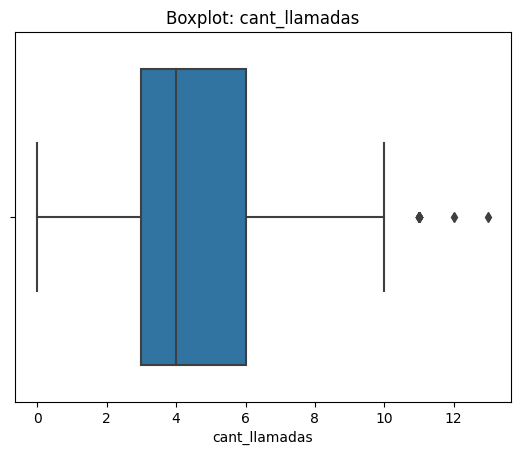

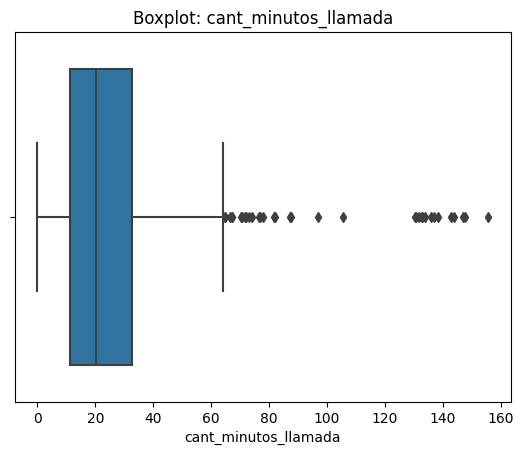

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile_2024[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: no presenta outliers)
- cant_mensajes: presenta outliers
- cant_llamadas: presenta outliers
- cant_minutos_llamada: presenta outliers

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile_2024[col].quantile(0.25)
    print('\nPrimer cuartil: ', Q1)

    Q3 = user_profile_2024[col].quantile(0.75)
    print('Tercer cuartil: ', Q3)
    
    IQR = Q3-Q1
    print('IQR: ', IQR)
    
    upper = Q3 + 1.5 * IQR
    print('Límite superior: ', upper)
    print()



Primer cuartil:  4.0
Tercer cuartil:  7.0
IQR:  3.0
Límite superior:  11.5


Primer cuartil:  3.0
Tercer cuartil:  6.0
IQR:  3.0
Límite superior:  10.5


Primer cuartil:  11.3325
Tercer cuartil:  32.5425
IQR:  21.209999999999997
Límite superior:  64.35749999999999



In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile_2024[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,1330.000000,1330.000000,1330.000000
mean,5.500000,4.557143,24.126669
std,2.382293,2.140329,19.458620
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.332500
50%,5.000000,4.000000,20.325000
75%,7.000000,6.000000,32.542500
max,16.000000,13.000000,155.690000


💡Insights: 
- cant_mensajes: mantener los outliers, porque a pesar de no ser tan cercanos a la media siguen estando en el límite de mensajes que ambos planes dan como parte de su servicio.
- cant_llamadas: mantener los outliers, porquea pesar de no ser tan cercanos a la media tampoco son valores extremadamente lejanos de los datos centrales.
- cant_minutos_llamada: mantener los outliers, porque a pesar de estar lejos de la media sigue estando dentro del límite de minutos incluidos en el servicio Premium.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso

import numpy as np

user_profile_2024['grupo_uso'] = np.where((user_profile_2024['cant_llamadas'] < 5) & (user_profile_2024['cant_mensajes'] < 5),'Bajo uso', np.where((user_profile_2024['cant_llamadas'] < 10) & (user_profile_2024['cant_mensajes'] < 10),'Uso medio','Alto uso'))



/tmp/ipykernel_34/3832428625.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_profile_2024['grupo_uso'] = np.where((user_profile_2024['cant_llamadas'] < 5) & (user_profile_2024['cant_mensajes'] < 5),'Bajo uso', np.where((user_profile_2024['cant_llamadas'] < 10) & (user_profile_2024['cant_mensajes'] < 10),'Uso medio','Alto uso'))


In [38]:
# verificar cambios
user_profile_2024.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
2666,12666,Mateo,Garcia,20.0,Cali,2024,Premium,NaN,13.0,3.0,11.50,Alto uso
2667,12667,Carlos,Gomez,72.0,Cali,2024,Premium,NaN,3.0,7.0,33.27,Uso medio
2668,12668,Ana,Torres,21.0,CDMX,2024,Basico,NaN,5.0,7.0,87.56,Uso medio
2669,12669,Sofia,Garcia,58.0,CDMX,2024,Basico,NaN,4.0,5.0,27.62,Uso medio
2670,12670,Ana,Garcia,54.0,MTY,2024,Premium,NaN,9.0,4.0,31.90,Uso medio


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
user_profile_2024['grupo_edad'] = np.where((user_profile_2024['age']< 30),'Joven', np.where((user_profile_2024['age']< 60),'Adulto','Adulto Mayor'))

/tmp/ipykernel_34/921562879.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_profile_2024['grupo_edad'] = np.where((user_profile_2024['age']< 30),'Joven', np.where((user_profile_2024['age']< 60),'Adulto','Adulto Mayor'))


In [40]:
# verificar cambios
user_profile_2024.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
2666,12666,Mateo,Garcia,20.0,Cali,2024,Premium,NaN,13.0,3.0,11.50,Alto uso,Joven
2667,12667,Carlos,Gomez,72.0,Cali,2024,Premium,NaN,3.0,7.0,33.27,Uso medio,Adulto Mayor
2668,12668,Ana,Torres,21.0,CDMX,2024,Basico,NaN,5.0,7.0,87.56,Uso medio,Joven
2669,12669,Sofia,Garcia,58.0,CDMX,2024,Basico,NaN,4.0,5.0,27.62,Uso medio,Adulto
2670,12670,Ana,Garcia,54.0,MTY,2024,Premium,NaN,9.0,4.0,31.90,Uso medio,Adulto


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

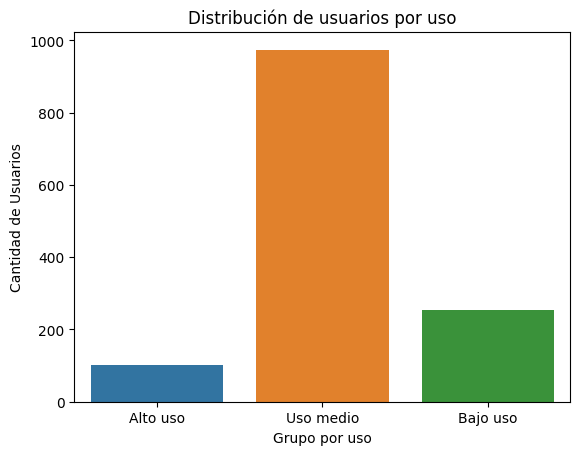

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile_2024, x='grupo_uso')

plt.title('Distribución de usuarios por uso')
plt.xlabel('Grupo por uso')
plt.ylabel('Cantidad de Usuarios')


plt.show()

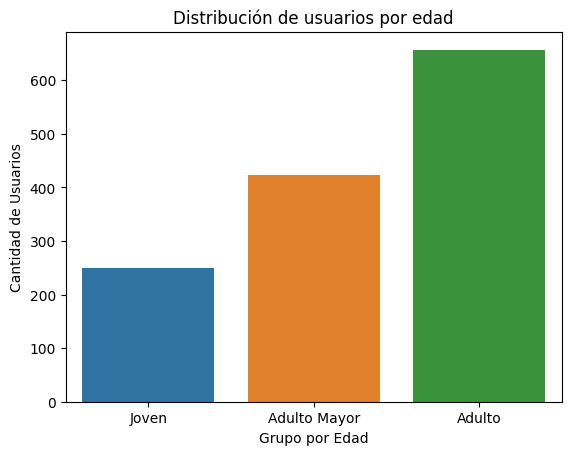

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile_2024, x='grupo_edad')

plt.title('Distribución de usuarios por edad')
plt.xlabel('Grupo por Edad')
plt.ylabel('Cantidad de Usuarios')

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En el dataset nombrado con la variable users, había 469 datos nulos en la columna 'city' y 3534 datos nulos en la columna 'churn_date', lo cual representaba un  11.73% y un 88.35% de valores nulos de sus repectivas columnas.
- En el dataset nombrado con la variable usage, había 50 datos nulos en la columna 'date', 22076 en la columna 'duration' y 17896 en la columna 'length', lo cual representaba un 0.13%, 55.19% y un 44.74% de valores nulos de sus repectivas columnas. 


🔍 **Segmentos por Edad**
- Se identificaron tres segmentos de clientes por edad: Joven, Adulto y Adulto mayor 
- El comportamiento de estos datos muestra que la mayor cantidad de clientes pertenece al grupo 'Adulto', en el cual se encuentran aquellas personas que tienen entre 30 y 60 años, el segundo grupo con mayor proporción de clientes es el de 'Adulto Mayor' en el cual se encuentran las personas mayores de 60 años, y por último, el segmento con menor proporción de clientes es el 'Joven' donde se encuntran aquellas personas menores de 30 años.


📊 **Segmentos por Nivel de Uso**
- Se identificiaron tres segmentos de clientes por uso: Bajo uso, Uso Medio y Alto uso
- El comportamiento de estos datos muestra que la mayor proporción de clientes le da un uso medio a su servicio, mientras que una menor proporción le da un bajo uso y solo una mínima proporción le da un alto uso.


➡️ Esto sugiere que a pesar de que los patrones de uso extremo (outliers) encontrados representan un comportamiento real de los datos, solo son una mínima proporción de clientes, por lo que el servicio no se debe enfocar en ellos, sino en el mayor segmento de clientes que se encuentran dentro de la distribución central de los datos y que son los que le dan un uso medio al servicio y tienen una edad de entre 30 y 60 años.


💡 **Recomendaciones**
- Podría crearse un tipo de plan intermedio, entre el el plan Básico y el plan Premium, el cual incluya una mayor cantidad de mensajes y llamadas que el plan Básico, pero una menor que el plan Premium y tenga un precio intermedio entre ambos planes.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`